## LDA LaBraM performance comparison

In [1]:
import os
from os import mkdir
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from core.datasets import KFoldSplitter, ClassFinetuneDataset
from core import settings, plot_data_processing
from core import io
from sklearn.linear_model import LogisticRegression

from core.io_models import Trial

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

labram_model_name = "class_nomask_10_22"
run_model_train = False

labram_model_dir = settings.FINETUNE_OUTPUT_DIR / labram_model_name
labram_inference_dir = settings.INFERENCE_DIR / labram_model_name
k_folds = 6
target_mode = "classify"  # the splitters load the input epochs only

# the same trials, window and labels as the LaBraM run: its baseline folds from keys.json, and every fold's post-patching
# test trials from the postpatch_keys.json its inference saved
if run_model_train:
    splitter = KFoldSplitter(input_data_dir=settings.FINETUNE_INPUT_EPOCHS_DIR, target_data_dir=None,
                             target_mode=target_mode, seed=settings.SEED, k_folds=k_folds,
                             no_press_threshold=settings.NO_PRESS_FROM_SUBJECT)

    folds = splitter.split_from_keys(io.load_training_split_keys(labram_model_dir, k_folds))

    postpatch_splitter = KFoldSplitter(input_data_dir=settings.PATCH_INPUT_EPOCHS_DIR, target_data_dir=None,
                                       target_mode=target_mode, seed=settings.SEED, k_folds=k_folds,
                                       no_press_threshold=settings.NO_PRESS_FROM_SUBJECT)
    postpatch_fold_keys = io.load_training_split_keys(labram_inference_dir, k_folds, filename="postpatch_keys.json")

    # interpolated channels of every trial, recorded in metadata["allowed"] (the non-masked LaBraM run saw them as normal inputs)
    interpolations_baseline = io.load_interpolated_channels(settings.FINETUNE_DIR / "epochs_manifest.csv")
    interpolations_postpatch = io.load_interpolated_channels(settings.PATCH_DIR / "epochs_manifest.csv")
    class_window = {"epoch_window": settings.EPOCH_WINDOW, "patch_window": settings.CLASS_PATCH_WINDOW, "fs": settings.RSFREQ,
                    "condition_classes": settings.CONDITION_CLASS_IDS}

    output_dir = settings.INFERENCE_DIR / "logistic_regression"
    for i, fold in enumerate(folds):

        train, val, test = fold.initialize_class_datasets(**class_window, interpolations=interpolations_baseline)
        postpatch_dataset = ClassFinetuneDataset(epochs_dict=postpatch_splitter.select(postpatch_fold_keys[i]["test"]),
                                                 **class_window, interpolations=interpolations_postpatch)

        X, y, meta = train.get_stacked_items()
        X_val, y_val, meta_val = val.get_stacked_items()
        X_test, y_test, meta_test = test.get_stacked_items()
        X_postpatch, y_postpatch, meta_postpatch = postpatch_dataset.get_stacked_items()

        # choose C based on validation
        best_score, best_model = 0, None
        for c in np.logspace(-4, 2, num=6):
            model = make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", solver="lbfgs", C=c, max_iter=2000, random_state=settings.SEED))
            model.fit(X, y)
            bal_acc = balanced_accuracy_score(y_val, model.predict(X_val))
            if bal_acc > best_score:
                best_score = bal_acc
                best_model = model
            print(f"Fold {i}, C={c:.4f}: Train R2={model.score(X, y):.4f}, Val R2={bal_acc:.4f}, Best R2={best_score:.4f}")

        test_logits = best_model.decision_function(X_test) # n trials x 8 (logits)
        postpatch_logits = best_model.decision_function(X_postpatch)

        print(f"Fold {i + 1}: test balanced accuracy {balanced_accuracy_score(y_test, test_logits.argmax(axis=1)):.4f}")

        # one file per session in the layout of run_inference.py: per trial the class id, the class logits as one row (1, n_classes),
        # so the mean over the first axis gives the class logits as for LaBraM's per-channel output, and the interpolated channels
        fold_dir = output_dir / str(i + 1)
        fold_dir.mkdir(parents=True, exist_ok=True)
        for session, logits, labels, metas in [("baseline", test_logits, y_test, meta_test), ("postpatch", postpatch_logits, y_postpatch, meta_postpatch)]:
            with h5py.File(fold_dir / f"{session}_reconstruction.h5", "w") as h5file:
                for trial_logits, label, trial_meta in zip(logits, labels, metas):
                    subj, cond, idx = trial_meta["subject"], trial_meta["condition"], trial_meta["id"]
                    io.save_inference_trial_hdf(subj, cond, idx, h5file, int(label), trial_logits[None, :], window_metrics={}, patch=None)
                    h5file[f"{subj}/{cond}/{idx}"].attrs["interpolated"] = np.flatnonzero(~trial_meta["allowed"].numpy())

In [3]:
from core import utils

# filters of the analysis, as in plasticity_plotting.ipynb. They select the trials loaded from the saved outputs only;
# the logistic regression above is trained on the same trials as LaBraM
subjects = None  # set to None to load all subjects
conditions = None  # set to None to load all location conditions; with a subset, the per-class AUCs of the missing classes can't be computed
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None  # set to None to load all trial ids
exclude_left_patched = True
exclude_right_patched_lefties = True  # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False  # set to True to exclude button press trials (everything before STMD59)

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))  # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)


In [4]:
# load the saved data
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]  # e.g. FP1, in the channel order of the outputs


def load_filtered_merged(model_name, mode="trial", ch_names=CH_NAMES):
    baseline_merged = []
    postpatch_merged = []

    for i in range(1, 7):
        b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
        p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"

        b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window="full", stim_patch=None)
        baseline_merged.extend(b_fold_trials)
        p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window="full", stim_patch=None)
        postpatch_merged.extend(p_fold_trials)
    if mode=="channel":
        b_c_df = plot_data_processing.class_channels_frame(baseline_merged, model_name, session="baseline", ch_names=ch_names)
        p_c_df = plot_data_processing.class_channels_frame(postpatch_merged, model_name, session="postpatch", ch_names=ch_names)
        return pd.concat([b_c_df, p_c_df], ignore_index=True)
    b_df = plot_data_processing.class_trials_frame(baseline_merged, model_name, session="baseline")
    p_df = plot_data_processing.class_trials_frame(postpatch_merged, model_name, session="postpatch")
    return pd.concat([b_df, p_df], ignore_index=True)

logreg_df = load_filtered_merged("logistic_regression", )
labram_df = load_filtered_merged("class_nomask_10_22")
labram_df["model"] = "labram"

masked_channel_df = load_filtered_merged("class_10_22", mode="channel")  # the masked class run, with occlusion


compare_df = pd.concat([logreg_df, labram_df], ignore_index=True)

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

In [5]:
def participant_scores(df: pd.DataFrame):
    proba = df[[f"p{k}" for k in range(8)]].to_numpy()
    auc = roc_auc_score(df["label"], proba, multi_class="ovr", average=None, labels=range(8))
    bal_acc = balanced_accuracy_score(df["label"], df["pred"])
    auc_format = {f"auc_{k}": a for k, a in enumerate(auc)}

    return pd.Series({"bal_acc": bal_acc, **auc_format, "n_trials": len(df)})


per_subj_scores = compare_df.groupby(["model", "session", "subject"]).apply(participant_scores).reset_index()

display(per_subj_scores.groupby(["model", "session"])["bal_acc"].agg(["mean", "sem", "count"]))

display(per_subj_scores.groupby(["model", "session"])[[f"auc_{k}" for k in range(8)]].agg(["mean"]))


mean       sem  count
model               session                             
labram              baseline   0.220997  0.006036     46
                    postpatch  0.214247  0.006915     46
logistic_regression baseline   0.234347  0.006379     46
                    postpatch  0.224304  0.007181     46

auc_0     auc_1     auc_2     auc_3  \
                                   mean      mean      mean      mean   
model               session                                             
labram              baseline   0.580583  0.639027  0.634145  0.599815   
                    postpatch  0.563971  0.640784  0.623749  0.590045   
logistic_regression baseline   0.595783  0.672482  0.682722  0.648420   
                    postpatch  0.593725  0.634005  0.651713  0.639675   

                                  auc_4     auc_5     auc_6     auc_7  
                                   mean      mean      mean      mean  
model               session                                            
labram              baseline   0.642552  0.624046  0.563276  0.601887  
                    postpatch  0.619868  0.628372  0.554177  0.596499  
logistic_regression baseline   0.665447  0.659258  0.580176  0.628508  
                    postpatch  0.657442  0.655832  0.581718  0.632662

In [6]:
per_subj_ch_masked = masked_channel_df.groupby(["session", "subject", "channel"])["occlusion_effect"].agg(["mean", "sem", "count"])

## Occlusion topomaps: change after patching
Masked LaBraM decoder (`class_10_22`): per channel, the drop of the true-class probability when the channel's cluster is
hidden, averaged per subject and session (interpolated channels left out), then over subjects. The change is post-patching
minus baseline per subject, shown as mean change and as d_z.
- **absolute**: the drop itself. The decoder was trained on baseline only, so post-patching trials are decoded less
  confidently overall, which makes every drop smaller: the absolute change mixes that with region-specific changes.
- **relative**: the drop as a share of the trial's true-class probability without hiding, which removes the overall
  confidence difference and shows whether the spatial pattern changed.

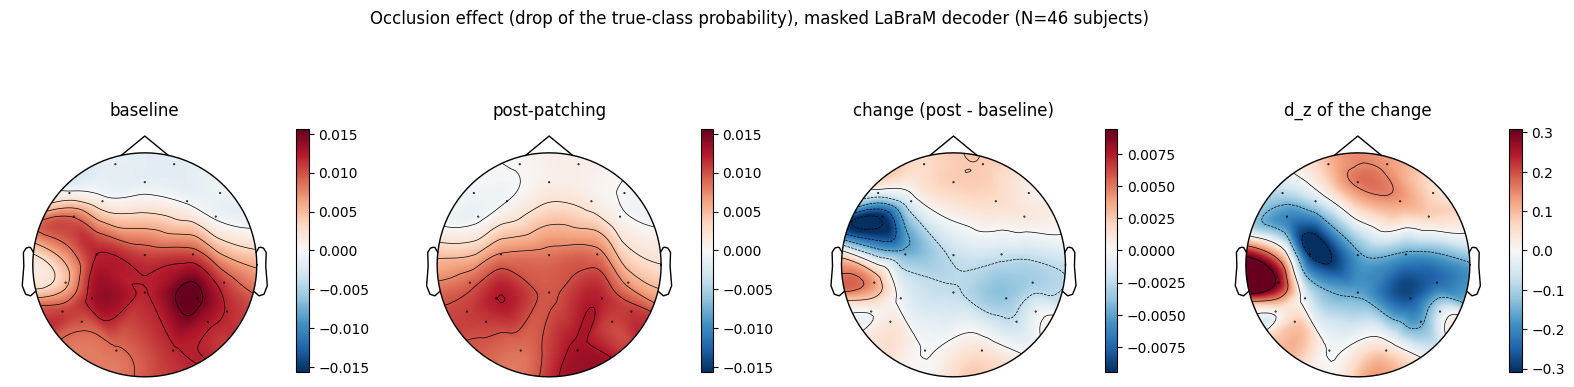

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: T3 +0.0038, FP2 +0.0024, FZ +0.0023
  min: F7 -0.0094, C3 -0.0043, P4 -0.0037


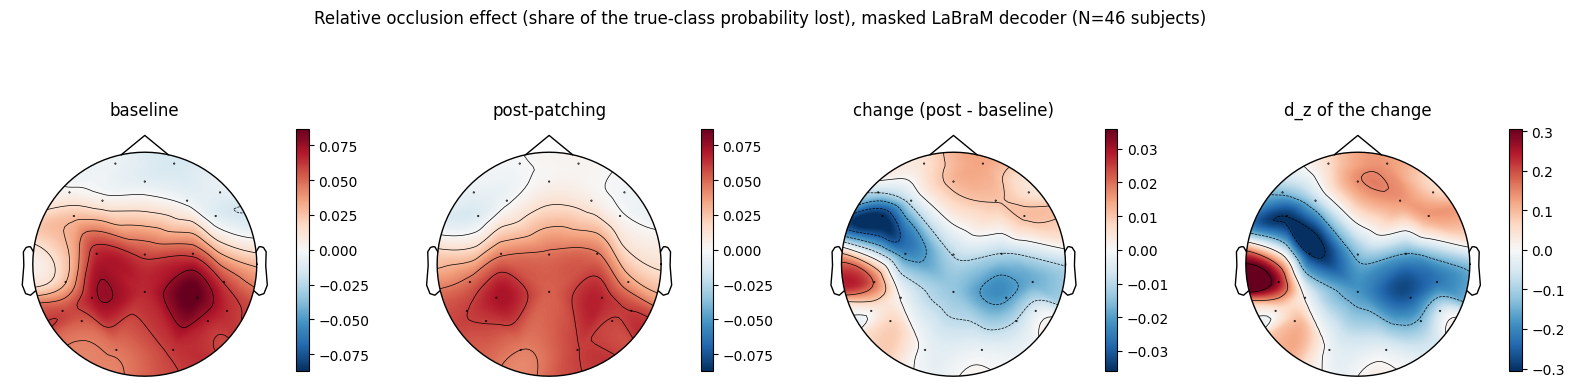

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: T3 +0.0193, FP2 +0.0140, FZ +0.0118
  min: F7 -0.0359, C3 -0.0233, P4 -0.0211


In [7]:
import matplotlib.pyplot as plt
import mne

topo_info = plot_data_processing.create_topomap_info()  # 10-20 labels at the HydroCel positions, in CH_NAMES order
# true-class probability without hiding = occlusion_effect + occluded_p_true
masked_channel_df["p_true"] = masked_channel_df["occlusion_effect"] + masked_channel_df["occluded_p_true"]


def channel_change_topomaps(df, label, value="occlusion_effect", relative=False, model_label="masked LaBraM decoder"):
    """
    Topomaps of a per-channel column of a channel table (class_channels_frame): the subject means per session (baseline
    and post-patching on one colour scale), the mean change (post-patching - baseline) and its d_z over the subjects with
    both sessions. NaN (interpolated) rows are left out of the subject means. Prints the 3 channels with the largest and
    the 3 with the smallest change.
    relative (occlusion only): the subject's mean drop divided by its mean true-class probability without hiding, per
    session and channel (a ratio of means: per-trial ratios explode for trials with a true-class probability near 0).
    """
    grouped = df.groupby(["session", "subject", "channel"])
    subject_means = grouped[value].mean()
    if relative:
        subject_means = subject_means / grouped["p_true"].mean()  # p_true is NaN on the same (interpolated) rows
    subject_means = subject_means.unstack("channel")[CH_NAMES]
    baseline, postpatch = subject_means.loc["baseline"], subject_means.loc["postpatch"]
    subjects = baseline.index.intersection(postpatch.index)
    change = postpatch.loc[subjects] - baseline.loc[subjects]
    maps = {"baseline": baseline.loc[subjects].mean(), "post-patching": postpatch.loc[subjects].mean(),
            "change (post - baseline)": change.mean(), "d_z of the change": change.mean() / change.std(ddof=1)}
    # the session maps share one scale: symmetric around 0 if the values can be negative, from min to max otherwise
    session_values = pd.concat([maps["baseline"], maps["post-patching"]])
    if session_values.min() < 0:
        session_vlim, session_cmap = (-session_values.abs().max(), session_values.abs().max()), "RdBu_r"
    else:
        session_vlim, session_cmap = (session_values.min(), session_values.max()), "viridis"

    fig, axes = plt.subplots(1, len(maps), figsize=(5 * len(maps), 4.5))
    for ax, (title, values) in zip(axes, maps.items()):
        session_map = title in ("baseline", "post-patching")
        vlim = session_vlim if session_map else (-values.abs().max(), values.abs().max())
        values = values.to_numpy(dtype=float)
        keep = np.flatnonzero(np.isfinite(values))
        im, _ = mne.viz.plot_topomap(values[keep], mne.pick_info(topo_info, keep), axes=ax, show=False, vlim=vlim,
                                     cmap=session_cmap if session_map else "RdBu_r")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.7)
    fig.suptitle(f"{label}, {model_label} (N={len(subjects)} subjects)", y=1.03)
    plt.show()

    ordered = maps["change (post - baseline)"].dropna().sort_values()
    print(f"{label}, change (post - baseline):")
    print("  max: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[::-1][:3].items()))
    print("  min: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[:3].items()))


channel_change_topomaps(masked_channel_df, "Occlusion effect (drop of the true-class probability)")
channel_change_topomaps(masked_channel_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True)


## Channel error without occlusion
The error of every channel's own row of LaBraM's output: 1 - its true-class probability (the softmax of the row alone),
the probability that the channel's vote is not the true location. Interpolated channels are left out. The rows come after
attention, so a channel's error reflects where the model routes its evidence, not what the channel measures by itself.
Shown for the masked and the regular LaBraM decoder.

In [ ]:
def add_channel_error(df):
    """1 - the true-class probability of every channel's row alone, NaN for interpolated channels."""
    df["channel_error"] = (1 - df["channel_p_true"]).where(~df["interpolated"])
    return df


nomask_channel_df = add_channel_error(load_filtered_merged("class_nomask_10_22", mode="channel"))
add_channel_error(masked_channel_df)
for df, model_label in ((nomask_channel_df, "LaBraM decoder without masking"), (masked_channel_df, "masked LaBraM decoder")):
    channel_change_topomaps(df, "Channel error (1 - true-class probability of the channel's row)", value="channel_error", model_label=model_label)


## Time-resolved decoding (Task A)
Sliding shrinkage LDA (`python -m decoding.run_sliding_lda --keys_from class_nomask_10_22`): one pooled model per fold,
session, band and time point on LaBraM's folds, trained within each session, features standardized per subject. Every
trial's -0.5 to 0.5 s window is band-passed into `DECODING_BANDS` (broadband: low-pass 45 Hz, keeps the slow evoked
response) and decimated to 100 Hz. The metrics are computed per subject from its out-of-fold test trials: balanced
accuracy (chance 1/8) and one-vs-rest AUC per class (chance 0.5) at every time point. The filters above select the subjects
and trials; run the cells per cohort (`exclude_button_press`) as the handoff asks, without pooling the cohorts.
Bars under the curves: time clusters above chance (one-sided cluster permutation test over subjects, p < 0.05).

In [ ]:
import h5py
import matplotlib.pyplot as plt
from core.decoding import metrics as decoding_metrics

sliding_name = "sliding_lda"  # output folder of decoding/run_sliding_lda.py
n_permutations = 5000


def load_time_metrics(name, file_suffix="reconstruction"):
    """
    Per-subject time metrics (decoding_metrics.time_metrics_frame) of both sessions of a sliding decoder, with the filters
    above, from its {session}_{file_suffix}.h5 files ("searchlight": the searchlight outputs, one set per channel).
    """
    run_dir = settings.INFERENCE_DIR / name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in ("baseline", "postpatch"):
        trials = []
        for k in folds:
            path = run_dir / str(k) / f"{session}_{file_suffix}.h5"
            with h5py.File(path, "r") as f:
                set_names, times = [str(s) for s in f.attrs["sets"]], np.asarray(f.attrs["times"])
            trials.extend(io.load_inference_trials(path, subjects=subjects, conditions=conditions, idxs=trial_ids,
                                                   exclude_subjects=exclude_subjects, stim_patch=None))
        frames.append(decoding_metrics.time_metrics_frame(trials, name, session, set_names, times, settings.N_LOCATION_CLASSES))
    return pd.concat(frames, ignore_index=True), set_names, times


time_df, set_names, times = load_time_metrics(sliding_name)
time_df.head()


In [ ]:
chance = 1 / settings.N_LOCATION_CLASSES
session_colors = {"baseline": "#2a78d6", "postpatch": "#eb6834"}
cluster_rows = []

fig, axes = plt.subplots(1, len(set_names), figsize=(4.5 * len(set_names), 4), sharey=True)
for ax, set_name in zip(axes, set_names):
    for offset, (session, color) in enumerate(session_colors.items()):
        curves = decoding_metrics.subject_curves(time_df, {"session": session, "set": set_name, "metric": "balanced_accuracy"})
        mean, err = curves.mean(), curves.sem()
        ax.plot(curves.columns, mean, color=color, label=f"{session} (N={len(curves)})")
        ax.fill_between(curves.columns, mean - err, mean + err, color=color, alpha=0.2, linewidth=0)
        for first, last, p in decoding_metrics.cluster_test_vs_chance(curves.to_numpy(), chance, n_permutations, settings.SEED):
            cluster_rows.append({"set": set_name, "session": session, "start": curves.columns[first], "end": curves.columns[last], "p": p})
            if p < 0.05:
                ax.hlines(chance - 0.004 * (offset + 1), curves.columns[first], curves.columns[last], color=color, linewidth=3)
    ax.axhline(chance, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(set_name)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("balanced accuracy")
axes[0].legend(frameon=False)
fig.suptitle("Location decoding over time, mean ± SEM over subjects (chance 1/8)", y=1.03)
plt.show()
display(pd.DataFrame(cluster_rows).round(3))


In [ ]:
# one-vs-rest AUC per class over time, primary set (broadband), per session
primary_set = set_names[0]
class_labels = {info["class_id"]: info["label"] for info in settings.LOCATION_CLASSES.values()}
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
for class_id, ax in zip(range(settings.N_LOCATION_CLASSES), axes.flat):
    for session, color in session_colors.items():
        curves = decoding_metrics.subject_curves(time_df, {"session": session, "set": primary_set, "metric": "auc", "class": class_id})
        mean, err = curves.mean(), curves.sem()
        ax.plot(curves.columns, mean, color=color, label=session)
        ax.fill_between(curves.columns, mean - err, mean + err, color=color, alpha=0.2, linewidth=0)
    ax.axhline(0.5, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(class_labels[class_id])
axes[0, 0].legend(frameon=False)
fig.suptitle(f"One-vs-rest AUC per location, {primary_set}, mean ± SEM over subjects (chance 0.5)", y=1.01)
plt.tight_layout()
plt.show()


## Side contrasts: latency and accuracy (Task B)
Per-class AUC curves of the primary set (broadband), classes relabelled per subject relative to the patched eye:
"patched" = the side of the patched eye, "other" the other side, "top" the top wall (`decoding_metrics.side_slots`).
- **Accuracy**: mean AUC in `Q4_ACCURACY_WINDOW`, fixed once from the baseline grand average (B1) before the post data are
  looked at. While it is None, the cell below suggests the largest baseline cluster above chance: write it into settings.
- **Latency**: the AUC curves smoothed over `Q4_LATENCY_SMOOTHING`, then the first time in `Q4_LATENCY_SEARCH` where the
  curve reaches `Q4_PEAK_FRACTION` of its peak above 0.5 (B2), on the mean curves, tested with the jackknife (B3).
- **Contrasts** (B5): Δ = post-patching - baseline per class, then patched - other side (near, mid, far) and top - mean of
  the sides (near, mid). Holm correction over the 10 change tests (5 contrasts x 2 measures); the baseline-only contrasts are
  reported alongside with their own correction.

In [ ]:
auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == primary_set)]

# B1: the accuracy window, from the baseline grand average over all classes only
if settings.Q4_ACCURACY_WINDOW is None:
    grand = auc_df[auc_df["session"] == "baseline"].groupby(["subject", "time"])["value"].mean().unstack("time")
    found = [c for c in decoding_metrics.cluster_test_vs_chance(grand.to_numpy(), 0.5, n_permutations, settings.SEED) if c[2] < 0.05]
    if not found:
        raise ValueError("No baseline cluster above chance, the accuracy window can't be chosen")
    first, last, p = max(found, key=lambda c: c[1] - c[0])
    accuracy_window = (round(float(grand.columns[first]), 3), round(float(grand.columns[last]), 3))
    print(f"Suggested Q4_ACCURACY_WINDOW = {accuracy_window} (baseline cluster p = {p:.4f}); write it into settings before looking at post data")
else:
    accuracy_window = settings.Q4_ACCURACY_WINDOW
print(f"Accuracy window: {accuracy_window} s")


In [ ]:
# per-subject class curves (n_subjects, n_classes, n_times) of both sessions, subjects with both sessions only
def class_curves(session):
    table = auc_df[auc_df["session"] == session].pivot_table(index=["subject", "class"], columns="time", values="value")
    return {s: table.loc[s].reindex(range(settings.N_LOCATION_CLASSES)).to_numpy() for s in table.index.get_level_values(0).unique()}


baseline_curves, postpatch_curves = class_curves("baseline"), class_curves("postpatch")
both = sorted(set(baseline_curves) & set(postpatch_curves))
eyes = decoding_metrics.patched_eyes(settings.DATA_ROOT / "eye_dominance.csv", settings.DATA_ROOT / "rightpatch_eye_dominance.csv")
baseline_slots, q4_subjects = decoding_metrics.side_slots(np.stack([baseline_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
postpatch_slots, _ = decoding_metrics.side_slots(np.stack([postpatch_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
curve_times = np.asarray(auc_df["time"].drop_duplicates().sort_values())
print(f"Q4 subjects with a known patched eye: {len(q4_subjects)} of {len(both)}")

# accuracy: mean AUC in the window; latency: smoothed curves, fractional peak latency on the mean curves (jackknife)
in_window = (curve_times >= accuracy_window[0] - 1e-9) & (curve_times <= accuracy_window[1] + 1e-9)
accuracy = decoding_metrics.accuracy_contrasts(baseline_slots[..., in_window].mean(-1), postpatch_slots[..., in_window].mean(-1))
smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
latency = decoding_metrics.latency_contrasts(curve_times, decoding_metrics.smooth(baseline_slots, smoothing),
                                             decoding_metrics.smooth(postpatch_slots, smoothing), 0.5,
                                             settings.Q4_PEAK_FRACTION, settings.Q4_LATENCY_SEARCH)
q4 = pd.concat([accuracy, latency], ignore_index=True)
for kind in ("change", "baseline only"):
    q4.loc[q4["kind"] == kind, "p_holm"] = decoding_metrics.holm(q4.loc[q4["kind"] == kind, "p"])
display(q4.round(4))


## Searchlight: where location is decodable
The same sliding LDA, trained on every channel's cluster alone (the channel and its nearest electrodes,
`run_sliding_lda.py --searchlight`, broadband by default), so every channel gets its own decoding accuracy over time.
Mapped: the balanced accuracy above chance in the Task B accuracy window, per session, the change (post-patching -
baseline) and its d_z over the subjects with both sessions. Neighbouring clusters share channels, so neighbouring
values are not independent.

In [ ]:
searchlight_df, cluster_names, _ = load_time_metrics(sliding_name, file_suffix="searchlight")
window_rows = searchlight_df[(searchlight_df["metric"] == "balanced_accuracy")
                             & searchlight_df["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
cluster_df = (window_rows.groupby(["session", "subject", "set"])["value"].mean() - chance).rename("searchlight_accuracy")
cluster_df = cluster_df.reset_index().rename(columns={"set": "channel"})
channel_change_topomaps(cluster_df, f"Searchlight balanced accuracy - chance, {accuracy_window[0]}-{accuracy_window[1]} s",
                        value="searchlight_accuracy", model_label="sliding LDA on every channel's cluster")
